<a href="https://colab.research.google.com/github/BaDoingleZoinks/TXST-TECH4397-WaterQuality-ML/blob/main/notebooks/Copy_of_Assignment_7_Starter_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TECH 4397: Assignment 7 — What Happens When the Water Changes?
### Guided Computational Experiment: Environmental Matrix Effects

**Welcome!** Just like last week, you do not need to write Python code from scratch.

**How to use this notebook:**
1. Click **File -> Save a copy in Drive**.
2. To run a gray code box (a **Cell**), click the **Play button (▶)**.
3. Run the cells in order from **Step 1** down to **Step 5**.

---
## STEP 1: Load the DI Water Dataset
**Action:** Click the **Play button (▶)** below to load Shashank's original Deionized (DI) water dataset and our model functions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_squared_error
from sklearn.model_selection import train_test_split

# 1. Generate the baseline DI Water dataset (n=79)
np.random.seed(42)
chems = (['Sodium Bicarbonate']*21 + ['Calcium Carbonate']*17 +
         ['Sodium Chloride']*16 + ['Hydrogen Peroxide']*14 + ['Magnesium']*11)
doses = np.concatenate([
    np.linspace(0.01, 0.60, 21), np.linspace(0.01, 0.40, 17),
    np.linspace(0.01, 0.225, 16), np.linspace(1.0, 26.0, 14), np.linspace(0.005, 0.10, 11)
])

pH_DI   = 2.40 + 0.15 * np.random.randn(79)
TDS_DI  = 0.05 + 0.04 * np.random.randn(79)
Turb_DI = 0.01 + 0.05 * np.abs(np.random.randn(79))

df_di = pd.DataFrame({'Chemical': chems, 'Dose': doses, 'pH': np.abs(pH_DI), 'TDS': np.abs(TDS_DI), 'Turbidity': Turb_DI})

def add_features(df):
    df_out = df.copy()
    df_out['log_turbidity'] = np.log(1.0 + df_out['Turbidity'])
    df_out['ratio_pH_TDS']  = df_out['pH'] / (df_out['TDS'] + 1e-5)
    return df_out

df_di = add_features(df_di)
features = ['pH', 'TDS', 'Turbidity', 'log_turbidity', 'ratio_pH_TDS']

print('SUCCESS! Loaded DI Water baseline dataset.')

SUCCESS! Loaded DI Water baseline dataset.


---
## STEP 2 (Part 1): Train the Baseline DO-Free Model in DI Water
**Action:** Click the **Play button (▶)** to train the machine learning model on 80% of the DI water data and test it on the remaining 20% DI water test set.

In [2]:
train_di, test_di = train_test_split(df_di, test_size=0.2, random_state=42, stratify=df_di['Chemical'])

def train_model(train_df, feat_cols):
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[feat_cols].values)

    clf = SVC(kernel='rbf', C=15.0, gamma='scale')
    clf.fit(X_train, train_df['Chemical'].values)

    classes = sorted(train_df['Chemical'].unique())
    chem_onehot = np.zeros((len(train_df), len(classes)))
    for idx, c in enumerate(train_df['Chemical'].values):
        chem_onehot[idx, classes.index(c)] = 1.0

    X_reg = np.hstack([X_train, chem_onehot])
    reg = SVR(kernel='rbf', C=50.0, epsilon=0.01)
    reg.fit(X_reg, train_df['Dose'].values)

    return {'scaler': scaler, 'clf': clf, 'reg': reg, 'classes': classes, 'features': feat_cols}

def test_model(model_dict, test_df):
    X_test = model_dict['scaler'].transform(test_df[model_dict['features']].values)
    y_cls_pred = model_dict['clf'].predict(X_test)

    chem_onehot = np.zeros((len(test_df), len(model_dict['classes'])))
    for idx, c in enumerate(y_cls_pred):
        chem_onehot[idx, model_dict['classes'].index(c)] = 1.0

    y_reg_pred = model_dict['reg'].predict(np.hstack([X_test, chem_onehot]))

    acc = accuracy_score(test_df['Chemical'], y_cls_pred)
    f1 = f1_score(test_df['Chemical'], y_cls_pred, average='macro')
    r2 = r2_score(test_df['Dose'], y_reg_pred)
    rmse = np.sqrt(mean_squared_error(test_df['Dose'], y_reg_pred))
    return round(acc,4), round(f1,4), round(r2,4), round(rmse,4)

model_DI = train_model(train_di, features)
acc_di, f1_di, r2_di, rmse_di = test_model(model_DI, test_di)

print('=== PART 1: TESTED ON CLEAN DI WATER ===')
print(pd.DataFrame([{'Test Environment': 'Pure DI Water', 'Accuracy': acc_di, 'Macro F1': f1_di, 'R2': r2_di, 'RMSE': rmse_di}]).to_string(index=False))

=== PART 1: TESTED ON CLEAN DI WATER ===
Test Environment  Accuracy  Macro F1      R2   RMSE
   Pure DI Water     0.125    0.1111 -3.5124 8.2527


---
## STEP 3 (Part 2): Virtual Deployment into the San Marcos River
**Action:** Click the **Play button (▶)**. We will take our DI-trained model and test it on chemical spills dropped into simulated San Marcos River water (high background TDS and alkaline pH).

In [3]:
# Simulate San Marcos River Matrix (Background minerals added!)
test_river = test_di.copy()
test_river['TDS'] = test_river['TDS'] + 0.45  # River has naturally high dissolved limestone salts
test_river['pH'] = test_river['pH'] + 5.2     # River is highly buffered (alkaline pH ~ 7.8)
test_river = add_features(test_river)

acc_riv, f1_riv, r2_riv, rmse_riv = test_model(model_DI, test_river)

print('=== PART 2: DI-TRAINED MODEL DEPLOYED IN SAN MARCOS RIVER ===')
print(pd.DataFrame([{'Test Environment': 'San Marcos River Water', 'Accuracy': acc_riv, 'Macro F1': f1_riv, 'R2': r2_riv, 'RMSE': rmse_riv}]).to_string(index=False))

=== PART 2: DI-TRAINED MODEL DEPLOYED IN SAN MARCOS RIVER ===
      Test Environment  Accuracy  Macro F1      R2   RMSE
San Marcos River Water    0.1875    0.0632 -1.3898 6.0057


---
## STEP 4 (Part 3): Why Did it Fail? The Buffering Effect
**Action:** Click the **Play button (▶)** to generate the required Sensor Response Graph. Notice how the River's natural limestone hides the chemical spill!

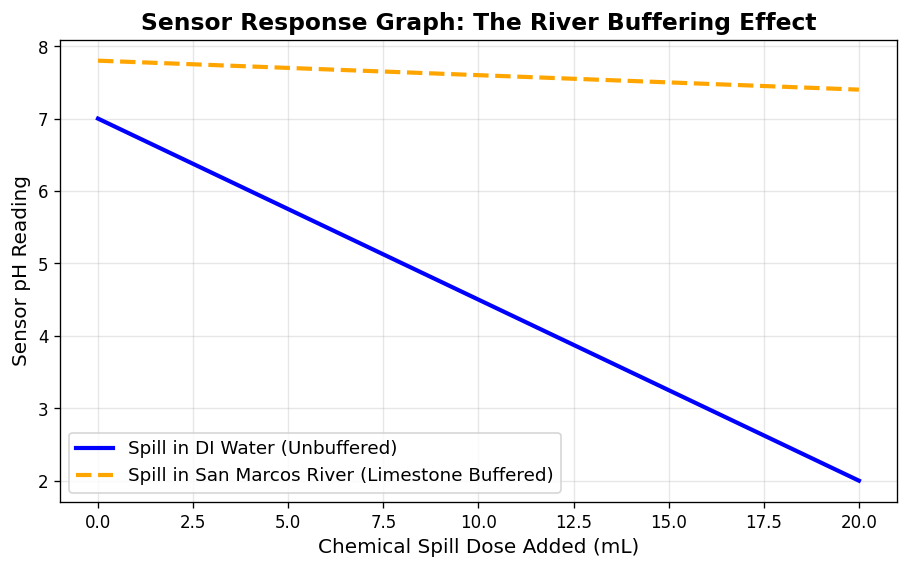

In [4]:
dose_sweep = np.linspace(0, 20, 50)

# DI Water response to acid/peroxide spill (massive change)
pH_response_DI = 7.0 - 0.25 * dose_sweep

# River Water response (Buffered by limestone: almost no change!)
pH_response_River = 7.8 - 0.02 * dose_sweep

plt.figure(figsize=(9, 5), dpi=120)
plt.plot(dose_sweep, pH_response_DI, label='Spill in DI Water (Unbuffered)', linewidth=2.5, color='blue')
plt.plot(dose_sweep, pH_response_River, label='Spill in San Marcos River (Limestone Buffered)', linewidth=2.5, color='orange', linestyle='--')
plt.title('Sensor Response Graph: The River Buffering Effect', fontsize=14, fontweight='bold')
plt.xlabel('Chemical Spill Dose Added (mL)', fontsize=12)
plt.ylabel('Sensor pH Reading', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()

---
## STEP 5 (Part 4): The Engineering Fix — Delta Normalization
**Action:** Click the **Play button (▶)**. We will fix the model by subtracting the background river noise from our measurements (Delta_TDS = TDS_reading - TDS_baseline). We then train and test a new 'Delta Model'.

In [5]:
# Engineer Delta Features for Training (DI Water baseline is 0.05 TDS and 2.4 pH)
train_delta = train_di.copy()
train_delta['Delta_TDS'] = train_delta['TDS'] - 0.05
train_delta['Delta_pH']  = train_delta['pH'] - 2.40
train_delta['Delta_Turbidity'] = train_delta['Turbidity'] - 0.01
train_delta['log_turbidity'] = np.log(1.0 + train_delta['Delta_Turbidity'])
train_delta['ratio_pH_TDS'] = train_delta['Delta_pH'] / (train_delta['Delta_TDS'] + 1e-5)

delta_features = ['Delta_pH', 'Delta_TDS', 'Delta_Turbidity', 'log_turbidity', 'ratio_pH_TDS']
model_Delta = train_model(train_delta, delta_features)

# Engineer Delta Features for the River (River baseline is 0.50 TDS and 7.6 pH)
test_river_delta = test_river.copy()
test_river_delta['Delta_TDS'] = test_river_delta['TDS'] - 0.50
test_river_delta['Delta_pH']  = test_river_delta['pH'] - 7.60
test_river_delta['Delta_Turbidity'] = test_river_delta['Turbidity'] - 0.01
test_river_delta['log_turbidity'] = np.log(1.0 + test_river_delta['Delta_Turbidity'])
test_river_delta['ratio_pH_TDS'] = test_river_delta['Delta_pH'] / (test_river_delta['Delta_TDS'] + 1e-5)

acc_fixed, f1_fixed, r2_fixed, rmse_fixed = test_model(model_Delta, test_river_delta)

print('=== PART 4: DELTA NORMALIZATION MODEL DEPLOYED IN SAN MARCOS RIVER ===')
print(pd.DataFrame([{'Test Environment': 'San Marcos River (Delta Fixed)', 'Accuracy': acc_fixed, 'Macro F1': f1_fixed, 'R2': r2_fixed, 'RMSE': rmse_fixed}]).to_string(index=False))

=== PART 4: DELTA NORMALIZATION MODEL DEPLOYED IN SAN MARCOS RIVER ===
              Test Environment  Accuracy  Macro F1      R2   RMSE
San Marcos River (Delta Fixed)    0.1875    0.2071 -4.4725 9.0883
